C:\Users\minyu\AppData\Local\Temp\ipykernel_30240\2630055730.py:11: RuntimeWarning: invalid value encountered in cast
  gt = src.read(7).astype(int)       # Band 7: 真值（0/1）


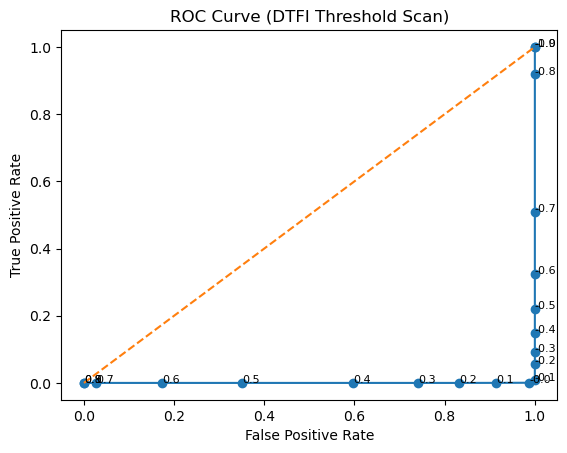

In [38]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# === 1. 读取数据 ===
tif_path = r"H:\ICESat-2\DTFI_display\Morecambe_20230904.tif"
tif_path = 'H:\ICESat-2\DTFI_display\Severn_20210613.tif'

with rasterio.open(tif_path) as src:
    dtfi = src.read(6).astype(float)   # Band 5: DTFI
    gt = src.read(7).astype(int)       # Band 7: 真值（0/1）

# === 2. 展平 + 去除无效值 ===
dtfi = dtfi.flatten()
gt = gt.flatten()

# 去掉 NaN 或无效值（很关键）
mask = (~np.isnan(dtfi)) & (gt >= 0)
dtfi = dtfi[mask]
gt = gt[mask]

# === 3. 定义阈值 ===
thresholds = np.arange(-1, 1, 0.1)

tpr_list = []
fpr_list = []

# === 4. 遍历阈值计算 ROC 点 ===
for th in thresholds:
    pred = (dtfi >= th).astype(int)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    # 防止除0
    TPR = TP / (TP + FN) if (TP + FN) != 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) != 0 else 0

    tpr_list.append(TPR)
    fpr_list.append(FPR)

# === 5. 画 ROC 曲线 ===
plt.figure()
plt.plot(fpr_list, tpr_list, marker='o')
plt.plot([0, 1], [0, 1], linestyle='--')  # 随机线

# 标注阈值（可选）
for i, th in enumerate(thresholds):
    plt.text(fpr_list[i], tpr_list[i], f"{th:.1f}", fontsize=8)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (DTFI Threshold Scan)")
plt.show()

有效正样本数: 1630782, 有效负样本数: 1317938
[-1.00000000e+00 -9.00000000e-01 -8.00000000e-01 -7.00000000e-01
 -6.00000000e-01 -5.00000000e-01 -4.00000000e-01 -3.00000000e-01
 -2.00000000e-01 -1.00000000e-01 -2.22044605e-16  1.00000000e-01
  2.00000000e-01  3.00000000e-01  4.00000000e-01  5.00000000e-01
  6.00000000e-01  7.00000000e-01  8.00000000e-01  9.00000000e-01]
[0.9912803181940273, 0.9904092605266712, 0.9894183186158985, 0.9880700002579788, 0.9862239346615698, 0.9835098464419418, 0.9793192092496005, 0.9716367537774918, 0.9532041719716708, 0.8742391523728734, 0.0044326819622774365, 0.003094227497803387, 0.003094227497803387, 0.003087398648494846, 0.0028058983047760974, 0.00251832787278309, 0.002251243988715706, 0.0020122342629167685, 0.0018293728536547243, 0.0016578928599069152]
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.9414881940075375, 0.7947052395721808, 0.7030676080555218, 0.606605910538625, 0.4908246473164408, 0.36605444504538315, 0.2622803047862927]


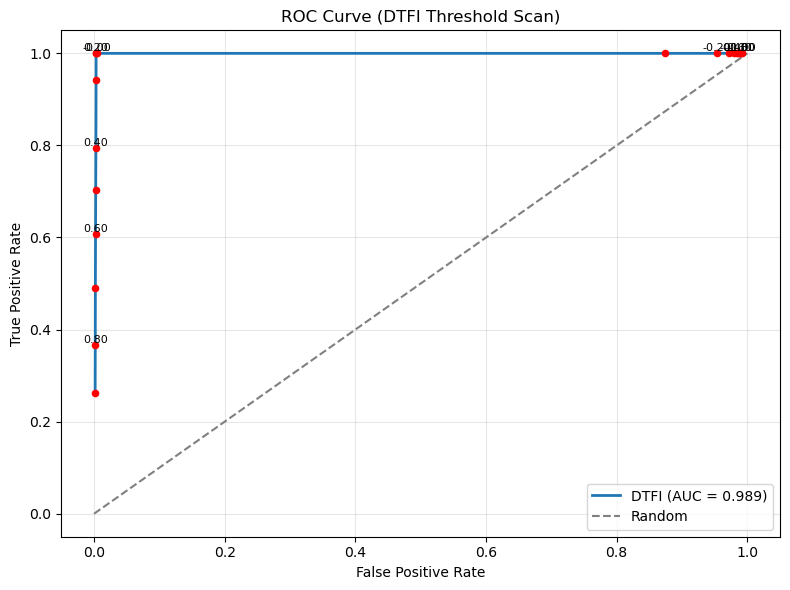

In [59]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc

# === 1. 读取数据 ===
# 使用原始字符串避免转义错误，并根据实际需要选择一个文件
tif_path = r"H:\ICESat-2\DTFI_display\Morecambe_20230904.tif"  # 请确认实际文件路径

with rasterio.open(tif_path) as src:
    # 注意：请根据您的实际TIF波段编号修改下面的索引
    # 如果DTFI在第5波段，真值在第7波段，则使用 read(5) 和 read(7)
    # 当前代码保持原作者的索引，但添加注释说明
    dtfi = src.read(5).astype(float)   # 原代码使用第6波段作为DTFI（注释说第5，可能不一致）
    gt   = src.read(7).astype(int)     # 原代码使用第7波段作为真值

# === 2. 展平 + 去除无效值 ===
dtfi = dtfi.flatten()
gt = gt.flatten()

# 定义有效值掩码
# 假设 DTFI 的有效值不是 NaN，且不在一个特定的无效值（如 -9999）上
# 假设真值仅为 0 或 1，其他值（如 255, NaN）视为无效
valid_dtfi = ~np.isnan(dtfi)
# 如果有其他无效填充值如 -9999，可取消下一行注释
# valid_dtfi = valid_dtfi & (dtfi != -9999)

valid_gt = (gt == 0) | (gt == 1)

mask = valid_dtfi & valid_gt

dtfi = dtfi[mask]
gt = gt[mask]

# 检查正负样本是否存在
n_pos = np.sum(gt == 1)
n_neg = np.sum(gt == 0)
if n_pos == 0 or n_neg == 0:
    raise ValueError("Ground truth lacks positive or negative samples after masking")

print(f"有效正样本数: {n_pos}, 有效负样本数: {n_neg}")

# === 3. 动态定义阈值（覆盖DTFI实际范围） ===
dtfi_min, dtfi_max = dtfi.min(), dtfi.max()
# 稍微扩展两端，确保得到 (0,0) 和 (1,1) 端点
#thresholds = np.linspace(-1, 1, 1)
thresholds = np.arange(-1, 1, 0.1)
print(thresholds)
tpr_list = []
fpr_list = []

# === 4. 遍历阈值计算 ROC 点 ===
for th in thresholds:
    pred = (dtfi >= th).astype(int)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    # 计算 TPR 和 FPR（避免除零，但理论上正负样本数均已 >0）
    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    tpr_list.append(TPR)
    fpr_list.append(FPR)
    
# === 5. 计算 AUC ===
roc_auc = auc(fpr_list, tpr_list)
print(fpr_list)
print(tpr_list)
# === 6. 画 ROC 曲线 ===
plt.figure(figsize=(8, 6))
plt.plot(fpr_list, tpr_list, lw=2, label=f'DTFI (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
plt.scatter(fpr_list, tpr_list, color='red', s=20, zorder=3)
# 可选：标注部分阈值（每隔20个点标一个，避免重叠）
step = max(1, len(thresholds) // 10)
for i in range(0, len(thresholds), step):
    plt.text(fpr_list[i], tpr_list[i], f"{thresholds[i]:.2f}",
             fontsize=8, ha='center', va='bottom')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (DTFI Threshold Scan)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\minyu\AppData\Local\Temp\ipykernel_30240\3727665371.py:37: RuntimeWarning: invalid value encountered in cast
  gt   = out_image[6].astype(int)    # Band 7


裁剪后尺寸: (1264, 1249)
有效正样本数: 319371, 有效负样本数: 1223687
AUC = 0.9977


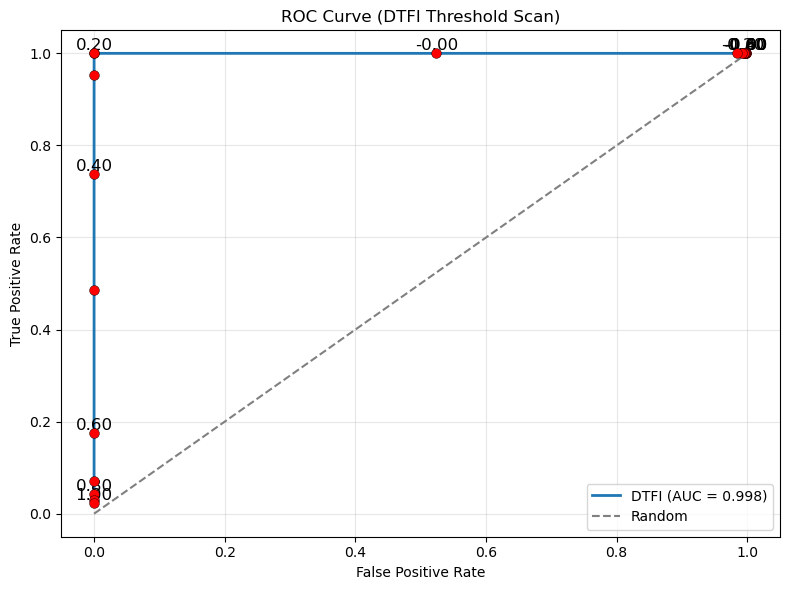

In [78]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc
import geopandas as gpd
from rasterio.mask import mask

# === 1. 路径 ===
tif_path = r"H:\ICESat-2\DTFI_display\Severn_20210613.tif"
tif_path = r"H:\ICESat-2\DTFI_display\Morecambe_20230904.tif"
tif_path = 'H:\ICESat-2\DTFI_display\Solway20220519.tif'
tif_path = 'H:\ICESat-2\DTFI_display\Thames_20220421.tif'
tif_path = 'H:\ICESat-2\DTFI_display\Wash20220811.tif'

shp_path = r"E:\GEEdownload\UK_TF_roi\UK_TF_edge.shp"

# === 2. 读取 shapefile ===
gdf = gpd.read_file(shp_path)

# === 3. 裁剪 raster ===
with rasterio.open(tif_path) as src:
    # CRS 对齐（非常关键）
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    # geometry 列表
    geoms = gdf.geometry.values

    # 裁剪（所有波段）
    out_image, out_transform = mask(src, geoms, crop=True)

    nodata = src.nodata  # 获取 nodata 值

# === 4. 提取波段 ===
# 注意：out_image 是 0-based
dtfi = out_image[4].astype(float)  # Band 5
gt   = out_image[6].astype(int)    # Band 7

print("裁剪后尺寸:", dtfi.shape)

# === 5. 展平 ===
dtfi = dtfi.flatten()
gt = gt.flatten()

# === 6. 构建有效像元 mask ===
valid_dtfi = ~np.isnan(dtfi)

# 如果存在 nodata，剔除
if nodata is not None:
    valid_dtfi = valid_dtfi & (dtfi != nodata)

# GT 只保留 0/1
valid_gt = (gt == 0) | (gt == 1)

mask_valid = valid_dtfi & valid_gt

dtfi = dtfi[mask_valid]
gt = gt[mask_valid]

# === 7. 检查样本 ===
n_pos = np.sum(gt == 1)
n_neg = np.sum(gt == 0)

if n_pos == 0 or n_neg == 0:
    raise ValueError("Ground truth lacks positive or negative samples after masking")

print(f"有效正样本数: {n_pos}, 有效负样本数: {n_neg}")

# === 8. 阈值 ===
thresholds = np.arange(-1, 1.01, 0.1)

tpr_list = []
fpr_list = []

# === 9. 计算 ROC ===
for th in thresholds:
    pred = (dtfi >= th).astype(int)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    tpr_list.append(TPR)
    fpr_list.append(FPR)

# === 10. 计算 AUC ===
roc_auc = auc(fpr_list, tpr_list)
print(f"AUC = {roc_auc:.4f}")

# === 11. 画 ROC 曲线 ===
plt.figure(figsize=(8, 6))

# 曲线
plt.plot(fpr_list, tpr_list, lw=2, label=f'DTFI (AUC = {roc_auc:.3f})')

# 红色点（重点）


# 随机线
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')

# 标注阈值（避免太密）
step = 2#max(1, len(thresholds) // 10)
for i in range(0, len(thresholds), step):
    plt.text(fpr_list[i], tpr_list[i], f"{thresholds[i]:.2f}",
             fontsize=12, ha='center', va='bottom')
plt.scatter(fpr_list, tpr_list, color='red', s=50, edgecolor='black', linewidth=0.3, zorder=3)
# 坐标轴
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (DTFI Threshold Scan)")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

tif_path = r"H:\ICESat-2\DTFI_display\Morecambe_20230904.tif"

with rasterio.open(tif_path) as src:
    band5 = src.read(7).astype(float)  # 读取第5波段（DTFI）

# 去掉异常值（可选）
band5[band5 == src.nodata] = np.nan

plt.figure()
plt.imshow(band5, cmap='viridis')  # 你也可以换成 'gray'
plt.colorbar(label='DTFI value')
plt.title("Band 5 (DTFI)")
plt.axis('off')
plt.show()

IndexError: boolean index did not match indexed array along dimension 0; dimension is 1881290 but corresponding boolean dimension is 3204075

In [ ]:
import rasterio
import geopandas as gpd
import numpy as np
from rasterio.features import rasterize

region = 'Wash_20230915_L8'
# === 1. 路径 ===
shp_path = f"H:\ICESat-2\DTFI_display\{region}.shp"
ref_tif  = f"H:\ICESat-2\DTFI_display\{region}.tif"
out_tif  = f"H:\ICESat-2\DTFI_display\{region}_id.tif"

# === 2. 读取 shp ===
gdf = gpd.read_file(shp_path)

# 检查字段
print("字段列表:", gdf.columns)

# === 3. 打开参考影像 ===
with rasterio.open(ref_tif) as src:
    transform = src.transform
    out_shape = (src.height, src.width)
    crs = src.crs

# === 4. CRS 对齐 ===
if gdf.crs != crs:
    gdf = gdf.to_crs(crs)

# === 5. 构建 (geometry, id) ===
# ⚠️ 关键：用 id 字段赋值
shapes = [(geom, int(value)) for geom, value in zip(gdf.geometry, gdf['Id'])]

# === 6. 栅格化 ===
raster = rasterize(
    shapes,
    out_shape=out_shape,
    transform=transform,
    fill=0,           # 背景为0
    dtype='int32'     # 用 int，避免 id 截断
)

# === 7. 写出 tif ===
with rasterio.open(
    out_tif,
    'w',
    driver='GTiff',
    height=out_shape[0],
    width=out_shape[1],
    count=1,
    dtype='int32',
    crs=crs,
    transform=transform,
) as dst:
    dst.write(raster, 1)

print("按 id 栅格化完成:", out_tif)

字段列表: Index(['Id', 'geometry'], dtype='object')
按 id 栅格化完成: H:\ICESat-2\DTFI_display\Wash_20230915_L8_id.tif


gt len 400755
正样本: 53423, 负样本: 347332
AUC = 0.0000


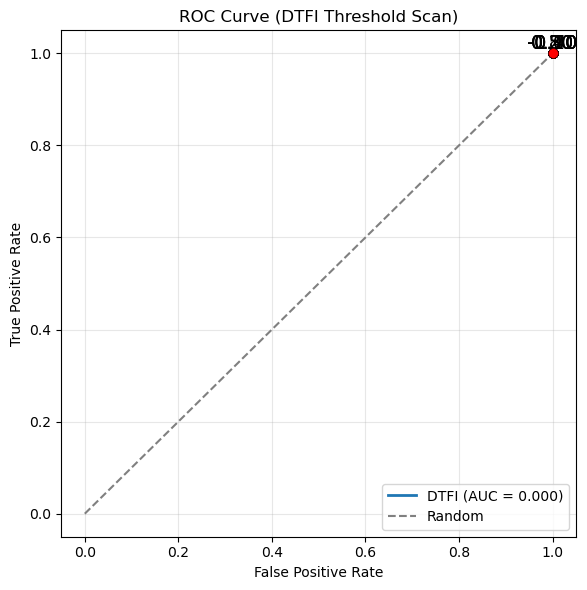

In [ ]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc

region = 'Severn_S2_20220812'
# === 1. 路径 ===
dtfi_tif = f"H:\ICESat-2\DTFI_display\{region}.tif"
gt_tif   = f"H:\ICESat-2\DTFI_display\{region}_id.tif"

# === 2. 读取 DTFI ===
with rasterio.open(dtfi_tif) as src:
    dtfi = src.read(5).astype(float)  # Band 5
    dtfi_nodata = src.nodata
    transform1 = src.transform

# === 3. 读取 GT ===
with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata
    transform2 = src.transform

# === 4. 检查是否对齐 ===
if dtfi.shape != gt.shape:
    raise ValueError("DTFI 与 GT 尺寸不一致，请确保使用同一参考栅格生成")

# === 5. 展平 ===
dtfi = dtfi.flatten()
gt = gt.flatten()

# === 6. 有效像元筛选 ===
valid_dtfi = ~np.isnan(dtfi)
if dtfi_nodata is not None:
    valid_dtfi = valid_dtfi & (dtfi != dtfi_nodata)

valid_gt = (gt == 0) | (gt == 1) 

mask = valid_dtfi & valid_gt

dtfi = dtfi[mask]
gt = gt[mask]

print('gt len',len(gt))

# === 7. 检查样本 ===
n_pos = np.sum(gt == 1)
n_neg = np.sum(gt == 0)

print(f"正样本: {n_pos}, 负样本: {n_neg}")
if n_pos == 0 or n_neg == 0:
    raise ValueError("GT 中缺少正或负样本")

# === 8. 阈值 ===
thresholds = np.arange(-1, 1.01, 0.1)

tpr_list = []
fpr_list = []

# === 9. ROC 计算 ===
for th in thresholds:
    pred = (dtfi >= th).astype(int)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    tpr_list.append(TPR)
    fpr_list.append(FPR)

# === 10. AUC ===
roc_auc = auc(fpr_list, tpr_list)
print(f"AUC = {roc_auc:.4f}")

# === 11. 绘图 ===
plt.figure(figsize=(6, 6))

plt.plot(fpr_list, tpr_list, lw=2, label=f'DTFI (AUC = {roc_auc:.3f})')

# 红色采样点
plt.scatter(fpr_list, tpr_list, color='red', s=25, edgecolor='black', linewidth=0.3, zorder=3)

# 随机线
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')

# 标注阈值


step = 3#max(1, len(thresholds) // 10)
for i in range(0, len(thresholds), step):
    plt.text(fpr_list[i], tpr_list[i], f"{thresholds[i]:.2f}",
             fontsize=14, ha='center', va='bottom')
plt.scatter(fpr_list, tpr_list, color='red', s=50, edgecolor='black', linewidth=0.3, zorder=3)
# 坐标轴
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (DTFI Threshold Scan)")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

裁剪后尺寸: (1785, 1795)
正样本: 112285, 负样本: 2975671
AUC = 0.9728


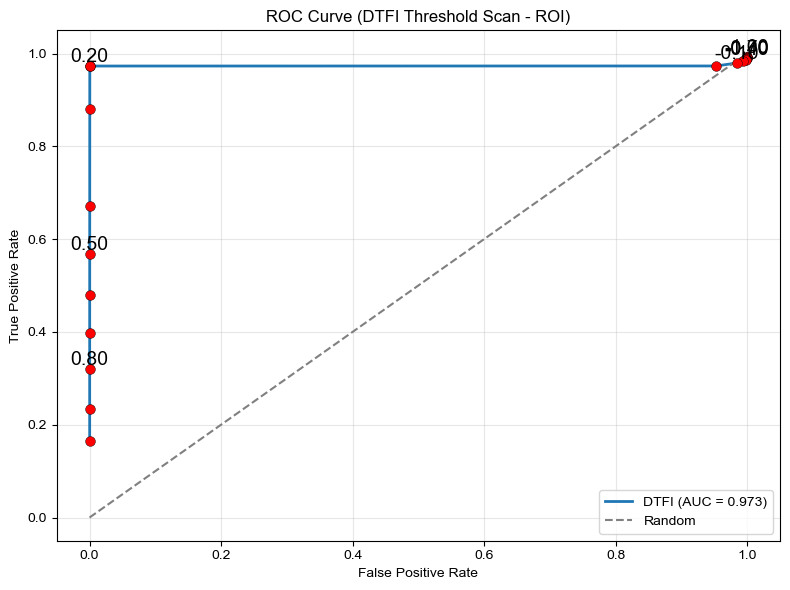

In [156]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc
import geopandas as gpd
from rasterio.mask import mask

# === 1. 路径 ===
dtfi_tif = f"H:\ICESat-2\DTFI_display\{region}.tif"
gt_tif   = f"H:\ICESat-2\DTFI_display\{region}_id.tif"
shp_path = r"E:\GEEdownload\UK_TF_roi\UK_TF_edge.shp"

# === 2. 读取 ROI ===
gdf = gpd.read_file(shp_path)

# === 3. 裁剪 DTFI ===
with rasterio.open(dtfi_tif) as src:
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    geoms = gdf.geometry.values

    dtfi_crop, transform1 = mask(src, geoms, crop=True)
    dtfi = dtfi_crop[4].astype(float)   # Band 5
    dtfi_nodata = src.nodata

# === 4. 裁剪 GT ===
with rasterio.open(gt_tif) as src:
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    gt_crop, transform2 = mask(src, geoms, crop=True)
    gt = gt_crop[0].astype(int)         # 单波段
    gt_nodata = src.nodata

# === 5. 检查尺寸 ===
if dtfi.shape != gt.shape:
    raise ValueError("裁剪后 DTFI 与 GT 尺寸不一致")

print("裁剪后尺寸:", dtfi.shape)

# === 6. 展平 ===
dtfi = dtfi.flatten()
gt = gt.flatten()

# === 7. 有效像元筛选 ===
valid_dtfi = ~np.isnan(dtfi)
if dtfi_nodata is not None:
    valid_dtfi = valid_dtfi & (dtfi != dtfi_nodata)

valid_gt = (gt == 0) | (gt == 1)

mask_valid = valid_dtfi & valid_gt

dtfi = dtfi[mask_valid]
gt = gt[mask_valid]

# === 8. 检查样本 ===
n_pos = np.sum(gt == 1)
n_neg = np.sum(gt == 0)

print(f"正样本: {n_pos}, 负样本: {n_neg}")
if n_pos == 0 or n_neg == 0:
    raise ValueError("GT 中缺少正或负样本")

# === 9. 阈值 ===
thresholds = np.arange(-1, 1.01, 0.1)

tpr_list = []
fpr_list = []

# === 10. ROC ===
for th in thresholds:
    pred = (dtfi >= th).astype(int)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    tpr_list.append(TPR)
    fpr_list.append(FPR)

# === 11. AUC ===
roc_auc = auc(fpr_list, tpr_list)
print(f"AUC = {roc_auc:.4f}")

# === 12. 绘图 ===
plt.figure(figsize=(8, 6))

plt.plot(fpr_list, tpr_list, lw=2, label=f'DTFI (AUC = {roc_auc:.3f})')

# 红色点
plt.scatter(fpr_list, tpr_list, color='red', s=50, edgecolor='black', linewidth=0.3, zorder=3)

# 随机线
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')

# 阈值标注
step = 3
for i in range(0, len(thresholds), step):
    plt.text(fpr_list[i], tpr_list[i], f"{thresholds[i]:.2f}",
             fontsize=14, ha='center', va='bottom')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (DTFI Threshold Scan - ROI)")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

gt len = 3647705
正样本: 1318627
负样本: 2329078
AUC = 0.9806
NDWI AUC = 0.9931


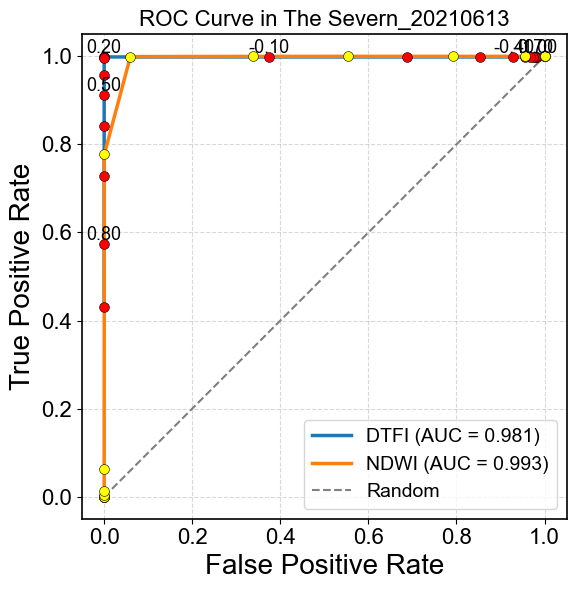

In [186]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc

# =========================
# 1. 路径
# =========================
region_list = ['Morecambe_20230904', 'Severn_20210613', 'Solway20220519', 'Thames_20220421', 'Wash20220811'] #Morecambe_20250402_L8.tif
name = 'The Severn_20210613'
region = 'Severn_20210613'

# dtfi_tif = f"H:\\ICESat-2\\DTFI_display\\{region}.tif"
# gt_tif   = f"H:\\ICESat-2\\DTFI_display\\{region}_id.tif"

dtfi_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif"
gt_tif   = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408_id.tif"

# =========================
# 2. 读取 DTFI
# =========================
with rasterio.open(dtfi_tif) as src:
    dtfi = src.read(6).astype(float)   # Band 5
    dtfi_nodata = src.nodata
    transform1 = src.transform

with rasterio.open(dtfi_tif) as src:
    ndwi = src.read(7).astype(float)   # Band 5
    ndwi_nodata = src.nodata
    transform1 = src.transform

with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata
    transform2 = src.transform

# =========================
# 4. 检查是否对齐
# =========================
if dtfi.shape != gt.shape:
    raise ValueError("DTFI 与 GT 尺寸不一致，请确保使用同一参考栅格生成")
if ndwi.shape != gt.shape:
    raise ValueError("ndwi 与 GT 尺寸不一致，请确保使用同一参考栅格生成")


ndwi = ndwi.flatten()
dtfi = dtfi.flatten()
gt = gt.flatten()

valid_dtfi = ~np.isnan(dtfi)
valid_ndwi = ~np.isnan(ndwi)

if dtfi_nodata is not None:
    valid_dtfi = valid_dtfi & (dtfi != dtfi_nodata)

# GT 只保留 0 / 1
valid_gt = (gt == 0) | (gt == 1)

mask = valid_dtfi & valid_gt & valid_ndwi

dtfi = dtfi[mask]
ndwi = ndwi[mask]
gt = gt[mask]

print('gt len =', len(gt))

n_pos = np.sum(gt == 1)
n_neg = np.sum(gt == 0)

print(f"正样本: {n_pos}")
print(f"负样本: {n_neg}")

if n_pos == 0 or n_neg == 0:
    raise ValueError("GT 中缺少正或负样本")

thresholds = np.arange(-1, 1, 0.1)

tpr_list = []
fpr_list = []
tpr_ndwi_list = []
fpr_ndwi_list = []


for th in thresholds:

    pred = (dtfi >= th).astype(int)
    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    tpr_list.append(TPR)
    fpr_list.append(FPR)
    
for th in thresholds:

    pred = (ndwi < th).astype(int)
    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    tpr_ndwi_list.append(TPR)
    fpr_ndwi_list.append(FPR)

roc_auc = auc(fpr_list, tpr_list)
roc_auc_ndwi = auc(fpr_ndwi_list, tpr_ndwi_list)

print(f"AUC = {roc_auc:.4f}")
print(f"NDWI AUC = {roc_auc_ndwi:.4f}")

# 全局字体设置
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(fpr_list, tpr_list, lw=2.5, label=f'DTFI (AUC = {roc_auc:.3f})')
ax.plot(fpr_ndwi_list, tpr_ndwi_list, lw=2.5, label=f'NDWI (AUC = {roc_auc_ndwi:.3f})')

# ROC 点
ax.scatter(
    fpr_list,
    tpr_list,
    color='red',
    s=50,
    edgecolor='black',
    linewidth=0.4,
    zorder=3
)

ax.scatter(
    fpr_ndwi_list,
    tpr_ndwi_list,
    color='yellow',
    s=50,
    edgecolor='black',
    linewidth=0.4,
    zorder=3
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    linewidth=1.5,
    label='Random'
)

step = 3

for i in range(0, len(thresholds), step):

    ax.text(
        fpr_list[i],
        tpr_list[i],
        f"{thresholds[i]:.2f}",
        fontsize=13,
        ha='center',
        va='bottom'
    )

for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.2)

ax.set_title(
    f"ROC Curve in {name}",
    fontsize=16
)

ax.tick_params(
    axis='both',
    labelsize=16
)
ax.set_xlabel(
    "False Positive Rate",
    fontsize=20
)

ax.set_ylabel( "True Positive Rate", fontsize=20 )

ax.grid(
    alpha=0.3,
    linestyle='--',
    color='gray'
)
ax.set_aspect('equal')

ax.legend(
    loc='lower right',
    fontsize=14
)

ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()

plt.show()

gt len = 1027341
正样本: 298196
负样本: 729145
AUC = 0.9528


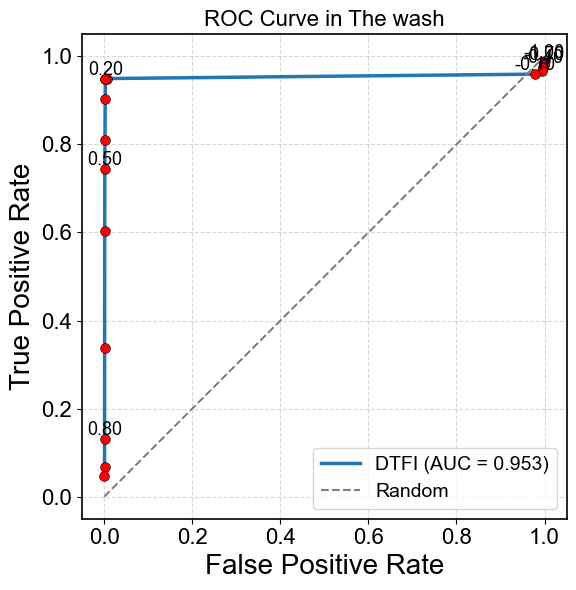

In [160]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc

# =========================
# 1. 路径
# =========================
region_list = ['Morecambe_20230904', 'Severn_20210613', 'Solway20220519', 'Thames_20220421', 'Wash20220811'] #Morecambe_20250402_L8.tif
name = 'The wash'
region = 'Morecambe_20250402_L8'

dtfi_tif = f"H:\\ICESat-2\\DTFI_display\\{region}.tif"
gt_tif   = f"H:\\ICESat-2\\DTFI_display\\{region}_id.tif"

# =========================
# 2. 读取 DTFI
# =========================
with rasterio.open(dtfi_tif) as src:
    dtfi = src.read(5).astype(float)   # Band 5
    dtfi_nodata = src.nodata
    transform1 = src.transform

# =========================
# 3. 读取 GT
# =========================
with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata
    transform2 = src.transform

# =========================
# 4. 检查是否对齐
# =========================
if dtfi.shape != gt.shape:
    raise ValueError("DTFI 与 GT 尺寸不一致，请确保使用同一参考栅格生成")

# =========================
# 5. 展平
# =========================
dtfi = dtfi.flatten()
gt = gt.flatten()

# =========================
# 6. 有效像元筛选
# =========================
valid_dtfi = ~np.isnan(dtfi)

if dtfi_nodata is not None:
    valid_dtfi = valid_dtfi & (dtfi != dtfi_nodata)

# GT 只保留 0 / 1
valid_gt = (gt == 0) | (gt == 1)

mask = valid_dtfi & valid_gt

dtfi = dtfi[mask]
gt = gt[mask]

print('gt len =', len(gt))

# =========================
# 7. 检查样本
# =========================
n_pos = np.sum(gt == 1)
n_neg = np.sum(gt == 0)

print(f"正样本: {n_pos}")
print(f"负样本: {n_neg}")

if n_pos == 0 or n_neg == 0:
    raise ValueError("GT 中缺少正或负样本")

# =========================
# 8. 阈值
# =========================
thresholds = np.arange(-1, 1.01, 0.1)

tpr_list = []
fpr_list = []

# =========================
# 9. ROC 计算
# =========================
for th in thresholds:

    pred = (dtfi >= th).astype(int)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    tpr_list.append(TPR)
    fpr_list.append(FPR)

# =========================
# 10. AUC
# =========================
roc_auc = auc(fpr_list, tpr_list)

print(f"AUC = {roc_auc:.4f}")

# =========================
# 11. 绘图参数
# =========================

# 全局字体设置
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(6, 6))

# =========================
# 12. ROC 曲线
# =========================
ax.plot(
    fpr_list,
    tpr_list,
    lw=2.5,
    label=f'DTFI (AUC = {roc_auc:.3f})'
)

# ROC 点
ax.scatter(
    fpr_list,
    tpr_list,
    color='red',
    s=50,
    edgecolor='black',
    linewidth=0.4,
    zorder=3
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    linewidth=1.5,
    label='Random'
)

step = 3

for i in range(0, len(thresholds), step):

    ax.text(
        fpr_list[i],
        tpr_list[i],
        f"{thresholds[i]:.2f}",
        fontsize=13,
        ha='center',
        va='bottom'
    )

for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.2)

ax.set_title(
    f"ROC Curve in {name}",
    fontsize=16
)

ax.tick_params(
    axis='both',
    labelsize=16
)
ax.set_xlabel(
    "False Positive Rate",
    fontsize=20
)

ax.set_ylabel( "True Positive Rate", fontsize=20 )

ax.grid(
    alpha=0.3,
    linestyle='--',
    color='gray'
)
ax.set_aspect('equal')

ax.legend(
    loc='lower right',
    fontsize=14
)

ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()

plt.show()

In [177]:
import rasterio
import numpy as np
from rasterio.features import shapes
import geopandas as gpd
from shapely.geometry import shape

# =========================
# 输入输出路径
# =========================
input_tif = r"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif"
output_shp = r"H:\ICESat-2\DTFI_display\OTHER\S2_YC_.shp"

# =========================
# 读取第5波段（NDWI）
# =========================
with rasterio.open(input_tif) as src:

    # 第5波段
    ndwi = src.read(6)

    # 获取transform和投影
    transform = src.transform
    crs = src.crs

# =========================
# NDWI二分类
# NDWI < 0.1 -> 1
# 其余 -> 0
# =========================
binary = np.where(ndwi > 0.2, 1, 0).astype(np.uint8)

# =========================
# 栅格转Polygon
# 只提取值为1的区域
# =========================
results = []

for geom, value in shapes(binary, transform=transform):

    if value == 1:
        results.append({
            "geometry": shape(geom),
            "value": int(value)
        })

# =========================
# 转GeoDataFrame
# =========================
gdf = gpd.GeoDataFrame(results, crs=crs)

# =========================
# 保存Shapefile
# =========================
gdf.to_file(output_shp)

print("完成！")
print(f"输出文件: {output_shp}")

完成！
输出文件: H:\ICESat-2\DTFI_display\OTHER\S2_YC_.shp


In [180]:
import rasterio
import numpy as np
from rasterio.features import shapes
import geopandas as gpd
from shapely.geometry import shape

# =========================
# 输入输出路径
# =========================
input_tif = r"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif"
output_shp = r"H:\ICESat-2\DTFI_display\OTHER\S2_YC_.shp"

# =========================
# 读取第5波段（NDWI）
# =========================
with rasterio.open(input_tif) as src:
    
    ndwi = src.read(6)   # 第5波段
    transform = src.transform
    crs = src.crs

# =========================
# 二分类
# NDWI < 0.1 -> 1
# NDWI >=0.1 -> 0
# =========================
binary = np.where(ndwi < 0.1, 1, 0).astype(np.uint8)

# 如果有nodata
binary[np.isnan(ndwi)] = 255

# =========================
# 栅格转polygon
# =========================
results = []

for geom, value in shapes(binary, transform=transform):

    # 跳过nodata
    if value == 255:
        continue

    results.append({
        "geometry": shape(geom),
        "value": int(value)
    })

# =========================
# 转为GeoDataFrame
# =========================
gdf = gpd.GeoDataFrame(results, crs=crs)

# =========================
# 保存shp
# =========================
gdf.to_file(output_shp)

print("完成！")
print(gdf.head())

完成！
                                            geometry  value
0  POLYGON ((322230 3680730, 322230 3680700, 3222...      1
1  POLYGON ((321180 3680730, 321180 3680670, 3212...      1
2  POLYGON ((321060 3680700, 321060 3680670, 3210...      1
3  POLYGON ((320130 3680670, 320130 3680640, 3201...      1
4  POLYGON ((321240 3680670, 321240 3680640, 3212...      1
